# 01 — Exploratory data analysis (Phase 2)

*18 November 2026. Reads the Parquet copies in `data/interim/` (made by `make interim` from the raw CSVs in
`data/home-credit-default-risk/`). Exploration only: nothing here is used for training. Every number quoted in
`data/README.md` and `reports/eda_summary.md` is produced by a cell below.*

The analysis is aimed at the decision, not at describing every column. It answers eight questions:

1. What is in each table and how do the tables join?
2. How often do applicants have payment difficulties, overall and by segment?
3. Where is data missing, and does missingness itself carry information?
4. Which values are placeholders or errors?
5. Which signals look strongest (a preview for Phases 4–5)?
6. Is anything dated after the application (leakage)?
7. Can the excluded attributes, gender and age, be recovered from the other columns (proxies)?
8. Does Kaggle's unlabelled test file look like the training file?

The memory budget is small (the tables total about 58 million rows), so related tables are loaded one at a time, with only the columns needed, and released afterwards.

**Reading guide for non-specialists.** *Default rate* here means the share of applicants with `TARGET = 1`
(payment difficulty on early instalments, not a write-off). The portfolio average is 8.07%; segments above it are riskier than average.

In [1]:
import gc, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, INT, FIG = ROOT/"data/home-credit-default-risk", ROOT/"data/interim", ROOT/"reports/figures"
FIG.mkdir(parents=True, exist_ok=True)
if not (INT/"installments_payments.parquet").exists():
    raise FileNotFoundError("data/interim is missing: run `make interim` first")

pd.set_option("display.width", 160, "display.max_columns", 30, "display.max_colwidth", 80)
BLUE, GREY, INK = "#2a78d6", "#8a8a85", "#2b2b29"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9c8c2", "axes.grid": True, "grid.color": "#ecebe6",
                     "axes.axisbelow": True, "font.size": 9.5, "axes.titleweight": "bold",
                     "axes.titlesize": 10.5, "text.color": INK, "axes.labelcolor": INK})

def load(table, cols=None):
    df = pd.read_parquet(INT/f"{table}.parquet", columns=cols)
    for c in df.columns:                      # pandas strings -> categories (less memory, NaN kept)
        if pd.api.types.is_string_dtype(df[c]) and not isinstance(df[c].dtype, pd.CategoricalDtype):
            df[c] = df[c].astype(object).where(df[c].notna(), np.nan).astype("category")
    return df

def pct(x, d=1): return f"{100*x:.{d}f}%"

def rate_bars(rates, sizes, title, fname, base, min_n=0, ax=None):
    """Horizontal bars of default rate per segment; dashed line = portfolio rate."""
    keep = sizes >= min_n
    r, n = rates[keep], sizes[keep]
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(6.4, 0.32*len(r)+1.0))
    ax.barh(range(len(r)), r*100, color=BLUE, height=0.62)
    ax.set_yticks(range(len(r)), [f"{k}  (n={v:,})" for k, v in zip(r.index.astype(str), n)])
    ax.invert_yaxis(); ax.axvline(base*100, color=GREY, ls="--", lw=1.2)
    for i, v in enumerate(r*100): ax.text(v+0.15, i, f"{v:.1f}%", va="center", fontsize=8)
    ax.set_xlabel(f"Default rate, % (dashed = portfolio {base*100:.2f}%)")
    ax.set_title(title, loc="left"); ax.grid(axis="y", visible=False)
    if own:
        plt.tight_layout(); plt.savefig(FIG/fname, bbox_inches="tight"); plt.show()

FACTS = {}   # every headline number, collected for the summary at the end

## 1. Tables, keys and joins

In [2]:
import pyarrow.parquet as pq
TABLES = ["application_train", "application_test", "bureau", "bureau_balance", "previous_application",
          "POS_CASH_balance", "installments_payments", "credit_card_balance"]
inv = pd.DataFrame([{"table": t, "rows": pq.ParquetFile(INT/f"{t}.parquet").metadata.num_rows,
                     "columns": pq.ParquetFile(INT/f"{t}.parquet").metadata.num_columns,
                     "raw CSV (MB)": round(os.path.getsize(RAW/f"{t}.csv")/1e6)} for t in TABLES])
FACTS["total_rows"] = int(inv.rows.sum())
inv

,table,rows,columns,raw CSV (MB)
0,application_train,307511,122,166
1,application_test,48744,121,27
2,bureau,1716428,17,170
3,bureau_balance,27299925,3,376
4,previous_application,1670214,37,405
5,POS_CASH_balance,10001358,8,393
6,installments_payments,13605401,8,723
7,credit_card_balance,3840312,23,425


In [3]:
app = load("application_train")
test_ids = load("application_test", ["SK_ID_CURR"]).SK_ID_CURR
y = app.set_index("SK_ID_CURR").TARGET
base = y.mean()
FACTS.update(n_train=len(app), n_cols=app.shape[1], base_rate=base, n_default=int(y.sum()),
             dup_ids=int(app.SK_ID_CURR.duplicated().sum()), overlap_test=len(set(app.SK_ID_CURR) & set(test_ids)))
print(f"application_train: {len(app):,} rows, {app.shape[1]} columns; duplicate IDs: {FACTS['dup_ids']}; "
      f"IDs shared with application_test: {FACTS['overlap_test']}")
print(f"Applicants with payment difficulty: {FACTS['n_default']:,} ({pct(base, 2)})")

application_train: 307,511 rows, 122 columns; duplicate IDs: 0; IDs shared with application_test: 0
Applicants with payment difficulty: 24,825 (8.07%)


**Join map.** `SK_ID_CURR` is the applicant (one row per application). Bureau credits hang off it via `SK_ID_BUREAU`;
earlier Home Credit loans via `SK_ID_PREV`. The coverage table below shows, for each related table, how many training
applicants have at least one row, how many rows there are per applicant, and how many keys fail to join upward.

In [4]:
cov = []
b = load("bureau", ["SK_ID_CURR", "SK_ID_BUREAU"])
bb_ids = load("bureau_balance", ["SK_ID_BUREAU"]).SK_ID_BUREAU
prev = load("previous_application", ["SK_ID_CURR", "SK_ID_PREV"])
def add(name, child_curr, n_rows, orphan_note):
    have = app.SK_ID_CURR.isin(child_curr)
    per = child_curr.value_counts()
    cov.append({"table": name, "rows": n_rows, "train applicants covered": pct(have.mean()),
                "rows per applicant (median / max)": f"{per.median():.0f} / {per.max():,}", "join check": orphan_note})
add("bureau", b.SK_ID_CURR, len(b), f"{pct(b.SK_ID_CURR.isin(test_ids).mean())} of rows belong to Kaggle test applicants")
cov.append({"table": "bureau_balance", "rows": len(bb_ids), "train applicants covered": "via bureau",
            "rows per applicant (median / max)": "monthly",
            "join check": f"{pct(1-bb_ids.isin(b.SK_ID_BUREAU).mean())} of rows have no parent in bureau; "
                          f"{pct(b.SK_ID_BUREAU.isin(bb_ids).mean())} of bureau credits have monthly history"})
add("previous_application", prev.SK_ID_CURR, len(prev), "earlier applications to Home Credit")
for t in ["POS_CASH_balance", "installments_payments", "credit_card_balance"]:
    d = load(t, ["SK_ID_CURR", "SK_ID_PREV"])
    mp = prev.drop_duplicates("SK_ID_PREV").set_index("SK_ID_PREV").SK_ID_CURR
    u = d.drop_duplicates("SK_ID_PREV"); m = u.SK_ID_PREV.map(mp)
    add(t, d.SK_ID_CURR, len(d), f"{pct(1-d.SK_ID_PREV.isin(prev.SK_ID_PREV).mean())} of rows: loan not in previous_application; "
        f"applicant mismatches: {int(((m.notna()) & (m != u.SK_ID_CURR)).sum())}")
    del d, u, m; gc.collect()
thin = ~app.SK_ID_CURR.isin(b.SK_ID_CURR)
FACTS.update(thin_n=int(thin.sum()), thin_share=thin.mean(), thin_rate=app.TARGET[thin].mean(),
             nonthin_rate=app.TARGET[~thin].mean(), prev_cover=app.SK_ID_CURR.isin(prev.SK_ID_CURR).mean())
del bb_ids; gc.collect()
pd.DataFrame(cov)

,table,rows,train applicants covered,rows per applicant (median / max),join check
0,bureau,1716428,85.7%,4 / 116,14.6% of rows belong to Kaggle test applicants
1,bureau_balance,27299925,via bureau,monthly,11.4% of rows have no parent in bureau; 45.1% of bureau credits have monthly...
2,previous_application,1670214,94.6%,4 / 77,earlier applications to Home Credit
3,POS_CASH_balance,10001358,94.1%,22 / 295,3.4% of rows: loan not in previous_application; applicant mismatches: 0
4,installments_payments,13605401,94.8%,25 / 372,9.2% of rows: loan not in previous_application; applicant mismatches: 0
5,credit_card_balance,3840312,28.3%,22 / 192,28.2% of rows: loan not in previous_application; applicant mismatches: 0


## 2. Target and base rates by segment

The unconditional rate sets the scale: a segment at 12% is half again as risky as the portfolio; one at 5% is about
40% safer. With the placeholder economics the break-even risk is 16.7%, so **no large segment is unprofitable on
average**; the money is in separating individuals, not in excluding groups.

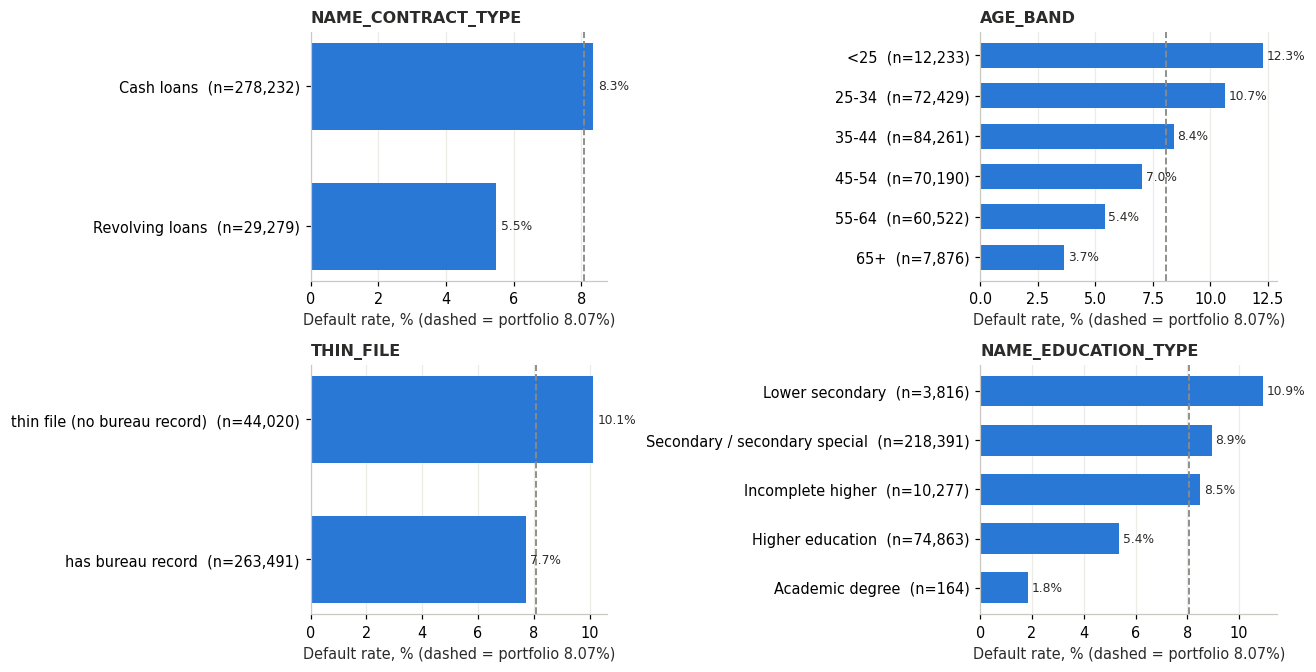

In [5]:
age = -app.DAYS_BIRTH/365.25
app["AGE_BAND"] = pd.cut(age, [18, 25, 35, 45, 55, 65, 75], right=False,
                         labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"])
app["THIN_FILE"] = np.where(thin, "thin file (no bureau record)", "has bureau record")
segs = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "AGE_BAND", "THIN_FILE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
        "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "REGION_RATING_CLIENT", "OCCUPATION_TYPE"]
seg_tab = {}
for s in segs:
    g = app.groupby(s, observed=True, dropna=False).TARGET.agg(["size", "mean"])
    g.index = g.index.astype(str).str.replace("nan", "(missing)")
    seg_tab[s] = g
fig, axes = plt.subplots(2, 2, figsize=(12, 6.2))
for ax, s in zip(axes.ravel(), ["NAME_CONTRACT_TYPE", "AGE_BAND", "THIN_FILE", "NAME_EDUCATION_TYPE"]):
    g = seg_tab[s] if s == "AGE_BAND" else seg_tab[s].sort_values("mean", ascending=False)
    rate_bars(g["mean"], g["size"], s, None, base, ax=ax)
plt.tight_layout(); plt.savefig(FIG/"02_default_rate_segments.png", bbox_inches="tight"); plt.show()

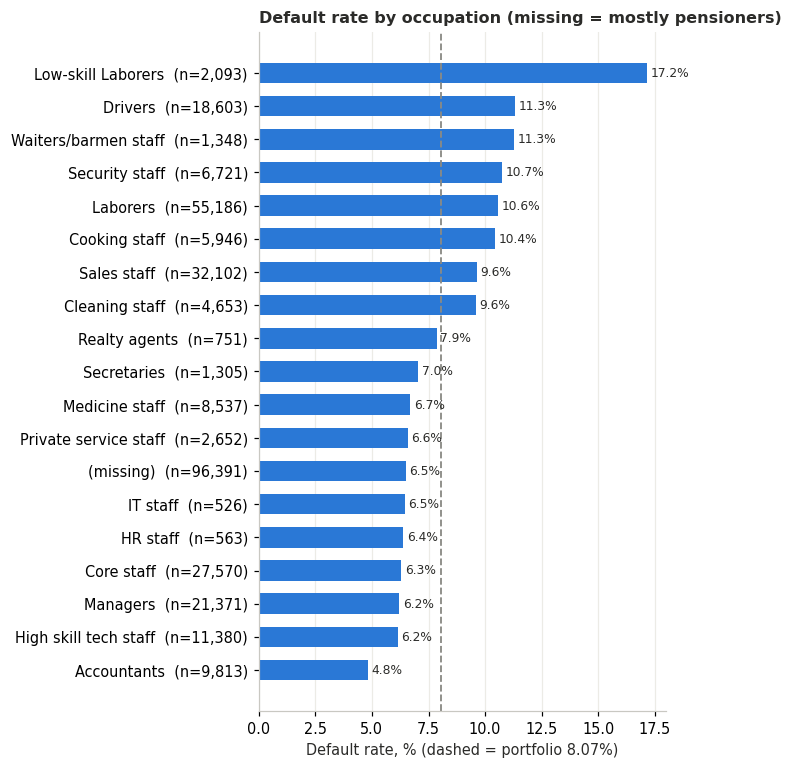

In [6]:
g = seg_tab["OCCUPATION_TYPE"].sort_values("mean", ascending=False)
rate_bars(g["mean"], g["size"], "Default rate by occupation (missing = mostly pensioners)", "02_default_rate_occupation.png", base)

In [7]:
rows = []
for s in segs:
    for k, r in seg_tab[s].iterrows():
        rows.append({"segment": s, "level": k, "n": int(r["size"]), "share": pct(r["size"]/len(app)), "default rate": pct(r["mean"])})
seg_long = pd.DataFrame(rows)
FACTS["seg"] = {s: seg_tab[s] for s in segs}
seg_long[seg_long.segment.isin(["CODE_GENDER", "AGE_BAND", "THIN_FILE", "NAME_CONTRACT_TYPE", "NAME_INCOME_TYPE"])]

,segment,level,n,share,default rate
0,NAME_CONTRACT_TYPE,Cash loans,278232,90.5%,8.3%
1,NAME_CONTRACT_TYPE,Revolving loans,29279,9.5%,5.5%
2,CODE_GENDER,F,202448,65.8%,7.0%
3,CODE_GENDER,M,105059,34.2%,10.1%
4,CODE_GENDER,XNA,4,0.0%,0.0%
5,AGE_BAND,<25,12233,4.0%,12.3%
6,AGE_BAND,25-34,72429,23.6%,10.7%
7,AGE_BAND,35-44,84261,27.4%,8.4%
8,AGE_BAND,45-54,70190,22.8%,7.0%
9,AGE_BAND,55-64,60522,19.7%,5.4%


**What this shows.** Risk falls steadily with age (12.3% under 25 to 3.7% at 65+), men default more than women
(10.1% vs 7.0%), and **thin-file applicants default at 10.1% vs 7.7%** for those with a bureau record. Thin-file
applicants are exactly the group the business wants to grow, and they are 25% riskier than the rest, so their slice
must be reported separately (D30). Revolving loans are safer (5.5%) but only 9.5% of rows. Small income-type levels
(Unemployed 22 rows, Maternity leave 5) show extreme rates that are noise and will be grouped.

## 3. Missing data

67 of 122 columns have missing values; 49 are more than 40% missing.
The 47 building columns (_AVG/_MODE/_MEDI) are missing together for 47.4% of applicants.


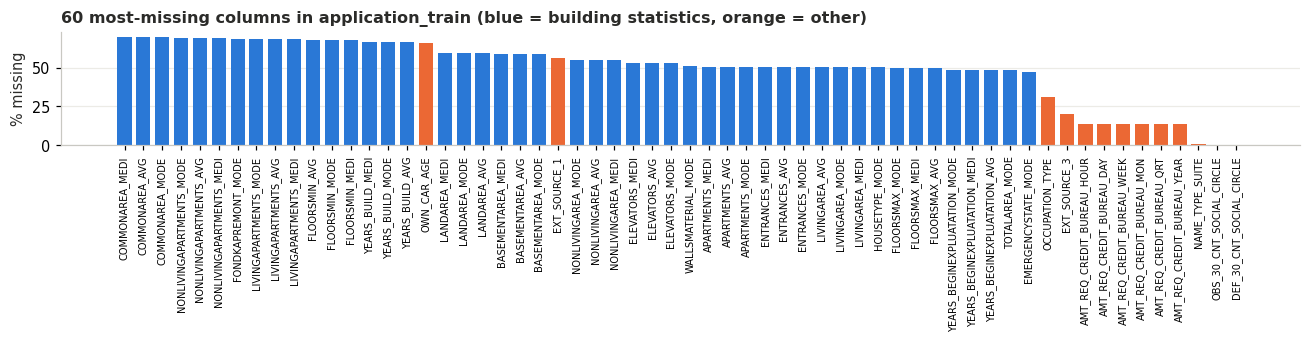

In [8]:
miss = app.drop(columns=["AGE_BAND", "THIN_FILE"]).isna().mean().sort_values(ascending=False)
FACTS["cols_missing_any"] = int((miss > 0).sum()); FACTS["cols_missing_40"] = int((miss > 0.4).sum())
hb = [c for c in app.columns if c.endswith(("_AVG", "_MODE", "_MEDI"))]
n_hb_missing = app[hb].isna().sum(axis=1)
all_missing = n_hb_missing == len(hb)
FACTS.update(n_housing=len(hb), housing_all_missing=all_missing.mean(),
             housing_rate_missing=app.TARGET[all_missing].mean(), housing_rate_present=app.TARGET[~all_missing].mean())
print(f"{FACTS['cols_missing_any']} of {len(miss)} columns have missing values; {FACTS['cols_missing_40']} are more than 40% missing.")
print(f"The {len(hb)} building columns (_AVG/_MODE/_MEDI) are missing together for {pct(all_missing.mean())} of applicants.")

top = miss.head(60)
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.bar(range(len(top)), top*100, color=[BLUE if c in hb else "#eb6834" for c in top.index], width=0.75)
ax.set_xticks(range(len(top)), top.index, rotation=90, fontsize=6.5); ax.set_ylabel("% missing")
ax.set_title("60 most-missing columns in application_train (blue = building statistics, orange = other)", loc="left")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.savefig(FIG/"03_missingness.png", bbox_inches="tight"); plt.show()

**Does missingness predict default?** If it does, missing values must be kept as information (a flag or a separate level), not silently filled.

In [9]:
check = ["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE", "OCCUPATION_TYPE", "AMT_REQ_CREDIT_BUREAU_YEAR", "APARTMENTS_AVG", "EXT_SOURCE_2"]
mt = pd.DataFrame([{"column": c, "% missing": round(100*app[c].isna().mean(), 1),
                    "default rate if missing": pct(app.TARGET[app[c].isna()].mean()),
                    "default rate if present": pct(app.TARGET[app[c].notna()].mean())} for c in check])
FACTS["miss_tab"] = mt
mt

,column,% missing,default rate if missing,default rate if present
0,EXT_SOURCE_1,56.4,8.5%,7.5%
1,EXT_SOURCE_3,19.8,9.3%,7.8%
2,OWN_CAR_AGE,66.0,8.5%,7.2%
3,OCCUPATION_TYPE,31.3,6.5%,8.8%
4,AMT_REQ_CREDIT_BUREAU_YEAR,13.5,10.3%,7.7%
5,APARTMENTS_AVG,50.7,9.2%,7.0%
6,EXT_SOURCE_2,0.2,7.9%,8.1%


Missingness is informative in both directions: a missing third external score goes with *higher* risk (9.3% vs 7.8%);
missing building data too (9.3% vs 7.0%); a missing occupation goes with *lower* risk (6.5%) because it is mostly
pensioners. `OWN_CAR_AGE` is missing when the applicant has no car (all 202,924 non-owners, plus 5 owners), so it needs no extra flag. `EXT_SOURCE_2` is almost never missing. Rule for Phase 3: missing-indicator flags
for these columns, and a separate level for missing categories.

## 4. Placeholders, errors and outliers

In [10]:
emp_na = app.DAYS_EMPLOYED == 365243
an = {
  "DAYS_EMPLOYED = 365243 (no-date marker)": f"{emp_na.sum():,} rows ({pct(emp_na.mean())}); income type: "
      + ", ".join(f"{k} {v:,}" for k, v in app.NAME_INCOME_TYPE[emp_na].value_counts().items() if v)
      + f"; default rate {pct(app.TARGET[emp_na].mean())}",
  "ORGANIZATION_TYPE = 'XNA'": f"{(app.ORGANIZATION_TYPE=='XNA').sum():,} rows; identical to the rows above: {bool(((app.ORGANIZATION_TYPE=='XNA')==emp_na).all())}",
  "CODE_GENDER = 'XNA'": f"{(app.CODE_GENDER=='XNA').sum()} rows",
  "AMT_INCOME_TOTAL": f"max {app.AMT_INCOME_TOTAL.max():,.0f} (that applicant defaulted); {(app.AMT_INCOME_TOTAL>1e6).sum()} rows above 1,000,000; 99.9th percentile {app.AMT_INCOME_TOTAL.quantile(.999):,.0f}",
  "CNT_CHILDREN": f"max {app.CNT_CHILDREN.max():.0f}; {(app.CNT_CHILDREN>=6).sum()} rows with 6 or more",
  "AMT_REQ_CREDIT_BUREAU_QRT": f"max {app.AMT_REQ_CREDIT_BUREAU_QRT.max():.0f} enquiries in a quarter (next highest {app.AMT_REQ_CREDIT_BUREAU_QRT.nlargest(2).iloc[1]:.0f})",
  "DAYS_LAST_PHONE_CHANGE = 0": f"{(app.DAYS_LAST_PHONE_CHANGE==0).sum():,} rows changed phone on the application day",
  "AMT_CREDIT / AMT_GOODS_PRICE": f"median {np.nanmedian(app.AMT_CREDIT/app.AMT_GOODS_PRICE):.3f}; the loan usually exceeds the goods price (fees or insurance)",
  "Near-constant flags": ", ".join(f"{c} ({int(app[c].sum()) if app[c].mean()<.5 else int((1-app[c]).sum())} rows differ)"
                                   for c in app.columns if c.startswith("FLAG_") and app[c].dtype!='category' and min(app[c].mean(), 1-app[c].mean())*len(app) < 100),
}
FACTS["emp_na_n"] = int(emp_na.sum()); FACTS["emp_na_rate"] = app.TARGET[emp_na].mean()
pd.DataFrame(an.items(), columns=["check (application_train)", "finding"])

,check (application_train),finding
0,DAYS_EMPLOYED = 365243 (no-date marker),"55,374 rows (18.0%); income type: Pensioner 55,352, Unemployed 22; default r..."
1,ORGANIZATION_TYPE = 'XNA',"55,374 rows; identical to the rows above: True"
2,CODE_GENDER = 'XNA',4 rows
3,AMT_INCOME_TOTAL,"max 117,000,000 (that applicant defaulted); 250 rows above 1,000,000; 99.9th..."
4,CNT_CHILDREN,max 19; 42 rows with 6 or more
5,AMT_REQ_CREDIT_BUREAU_QRT,max 261 enquiries in a quarter (next highest 19)
6,DAYS_LAST_PHONE_CHANGE = 0,"37,672 rows changed phone on the application day"
7,AMT_CREDIT / AMT_GOODS_PRICE,median 1.119; the loan usually exceeds the goods price (fees or insurance)
8,Near-constant flags,"FLAG_MOBIL (1 rows differ), FLAG_DOCUMENT_2 (13 rows differ), FLAG_DOCUMENT_..."


In [11]:
bu = load("bureau")
prev_full = load("previous_application")
inst = load("installments_payments", ["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER", "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"])
early = inst.DAYS_ENTRY_PAYMENT - inst.DAYS_INSTALMENT
rel = {
  "bureau: DAYS_CREDIT_ENDDATE < -40,000 days (~110 years)": f"{(bu.DAYS_CREDIT_ENDDATE < -40000).sum()} rows",
  "bureau: DAYS_CREDIT_UPDATE < -40,000": f"{(bu.DAYS_CREDIT_UPDATE < -40000).sum()} rows",
  "bureau: credit ends before it starts": f"{(bu.DAYS_ENDDATE_FACT < bu.DAYS_CREDIT).sum()} rows",
  "bureau: negative AMT_CREDIT_SUM_DEBT / LIMIT": f"{(bu.AMT_CREDIT_SUM_DEBT<0).sum():,} / {(bu.AMT_CREDIT_SUM_LIMIT<0).sum():,} rows",
  "bureau: status 'Closed' but no end date / 'Active' with an end date": f"{((bu.CREDIT_ACTIVE=='Closed') & bu.DAYS_ENDDATE_FACT.isna()).sum()} / {((bu.CREDIT_ACTIVE=='Active') & bu.DAYS_ENDDATE_FACT.notna()).sum():,}",
  "bureau: non-main currency": f"{(bu.CREDIT_CURRENCY!='currency 1').sum():,} rows ({pct((bu.CREDIT_CURRENCY!='currency 1').mean(), 2)})",
  "previous_application: 365243 in the five DAYS_ columns": ", ".join(f"{c.replace('DAYS_','')} {(prev_full[c]==365243).sum():,}" for c in ["DAYS_FIRST_DRAWING","DAYS_FIRST_DUE","DAYS_LAST_DUE_1ST_VERSION","DAYS_LAST_DUE","DAYS_TERMINATION"]),
  "previous_application: AMT_CREDIT = 0": f"{(prev_full.AMT_CREDIT==0).sum():,} rows (refused, cancelled or unused applications)",
  "previous_application: SELLERPLACE_AREA = -1": f"{(prev_full.SELLERPLACE_AREA==-1).sum():,} rows (no-value marker)",
  "previous_application: RATE_INTEREST_* missing": pct(prev_full.RATE_INTEREST_PRIMARY.isna().mean()),
  "installments: repeated (loan, version, number)": f"{inst.duplicated(['SK_ID_PREV','NUM_INSTALMENT_VERSION','NUM_INSTALMENT_NUMBER']).sum():,} rows (split payments)",
  "installments: paid more than 365 days early": f"{(early < -365).sum():,} rows",
  "installments: payment missing": f"{inst.AMT_PAYMENT.isna().sum():,} rows",
}
pd.DataFrame(rel.items(), columns=["check (related tables)", "finding"])

,check (related tables),finding
0,"bureau: DAYS_CREDIT_ENDDATE < -40,000 days (~110 years)",134 rows
1,"bureau: DAYS_CREDIT_UPDATE < -40,000",95 rows
2,bureau: credit ends before it starts,20 rows
3,bureau: negative AMT_CREDIT_SUM_DEBT / LIMIT,"8,418 / 351 rows"
4,bureau: status 'Closed' but no end date / 'Active' with an end date,"125 / 1,969"
5,bureau: non-main currency,"1,408 rows (0.08%)"
6,previous_application: 365243 in the five DAYS_ columns,"FIRST_DRAWING 934,444, FIRST_DUE 40,645, LAST_DUE_1ST_VERSION 93,864, LAST_D..."
7,previous_application: AMT_CREDIT = 0,"336,768 rows (refused, cancelled or unused applications)"
8,previous_application: SELLERPLACE_AREA = -1,"762,675 rows (no-value marker)"
9,previous_application: RATE_INTEREST_* missing,99.6%


None of these is large, but each would quietly distort an aggregate: a 110-year credit inflates "average credit
length", a split payment looks like an under-payment followed by an over-payment, and 0 in `AMT_CREDIT` of a refused
application would drag down "average previous loan size". The handling rule for each is in `reports/leakage_table.md`.

## 5. Strongest signals (preview)

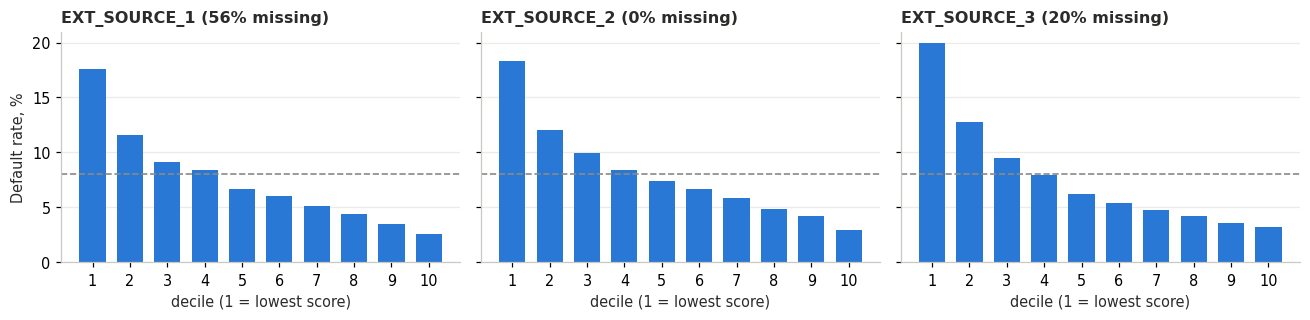

Single-score ROC-AUC (where present): {'EXT_SOURCE_1': 0.666, 'EXT_SOURCE_2': 0.656, 'EXT_SOURCE_3': 0.679}


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.0), sharey=True)
for ax, c in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    q = pd.qcut(app[c], 10, labels=False, duplicates="drop")
    r = app.groupby(q).TARGET.mean()*100
    ax.bar(r.index+1, r.values, color=BLUE, width=0.7); ax.axhline(base*100, color=GREY, ls="--", lw=1.1)
    ax.set_title(f"{c} ({app[c].isna().mean()*100:.0f}% missing)", loc="left"); ax.set_xlabel("decile (1 = lowest score)")
    ax.set_xticks(range(1, 11)); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Default rate, %"); plt.tight_layout(); plt.savefig(FIG/"05_ext_source_deciles.png", bbox_inches="tight"); plt.show()
from sklearn.metrics import roc_auc_score
auc = {c: roc_auc_score(app.TARGET[app[c].notna()], -app[c].dropna()) for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]}
FACTS["ext_auc"] = auc; FACTS["ext_dec"] = {c: (app.groupby(pd.qcut(app[c], 10, labels=False)).TARGET.mean().iloc[[0, -1]].tolist()) for c in auc}
print("Single-score ROC-AUC (where present):", {k: round(v, 3) for k, v in auc.items()})

In [13]:
sig = []
over = (bu.CREDIT_DAY_OVERDUE > 0).groupby(bu.SK_ID_CURR).max()
j = y.to_frame().join(over.rename("x"), how="inner")
for k, g in j.groupby("x"): sig.append({"signal": "bureau: any credit overdue at application", "group": "yes" if k else "no", "n": len(g), "default rate": pct(g.TARGET.mean())})
ref = (prev_full.NAME_CONTRACT_STATUS == "Refused").groupby(prev_full.SK_ID_CURR).mean()
j = y.to_frame().join(ref.rename("x"), how="inner")
for k, g in j.groupby(pd.cut(j.x, [-.01, 0, .25, .5, 1.01], labels=["none", "up to 25%", "25-50%", "over 50%"]), observed=True):
    sig.append({"signal": "share of earlier applications refused", "group": k, "n": len(g), "default rate": pct(g.TARGET.mean())})
late = (early > 0).groupby(load("installments_payments", ["SK_ID_CURR"]).SK_ID_CURR).mean()
j = y.to_frame().join(late.rename("x"), how="inner")
for k, g in j.groupby(pd.cut(j.x, [-.01, 0, .05, .2, 1.01], labels=["never", "up to 5%", "5-20%", "over 20%"]), observed=True):
    sig.append({"signal": "share of earlier instalments paid late", "group": k, "n": len(g), "default rate": pct(g.TARGET.mean())})
rec = bu.SK_ID_CURR[bu.DAYS_CREDIT >= -7]
f = app.SK_ID_CURR.isin(rec)
sig.append({"signal": "bureau credit opened in the 7 days before applying", "group": "yes", "n": int(f.sum()), "default rate": pct(app.TARGET[f].mean())})
FACTS["signals"] = pd.DataFrame(sig)
del late, j; gc.collect()
FACTS["signals"]

,signal,group,n,default rate
0,bureau: any credit overdue at application,no,260094,7.6%
1,bureau: any credit overdue at application,yes,3397,15.9%
2,share of earlier applications refused,none,190763,7.1%
3,share of earlier applications refused,up to 25%,47397,8.1%
4,share of earlier applications refused,25-50%,41739,11.3%
5,share of earlier applications refused,over 50%,11158,15.9%
6,share of earlier instalments paid late,never,136644,6.8%
7,share of earlier instalments paid late,up to 5%,40212,7.0%
8,share of earlier instalments paid late,5-20%,77325,9.4%
9,share of earlier instalments paid late,over 20%,37462,12.0%


The three external scores are by far the strongest single inputs (single-score AUC 0.66–0.68 where present; the lowest
decile defaults at 18–20%, the highest at about 3%). The related tables add behaviour the main table lacks: applicants
with a bureau credit currently overdue default at about twice the average, and so do applicants most of whose earlier
applications were refused. These will be the first aggregates built in Phase 3 (ablations B and C).

## 6. Leakage audit: is anything dated after the application?

Every date in this data set is stored as days (or months) **relative to the application**: negative = before,
positive = after. A model may only use what existed at decision time, so every positive value must be explained.
The value 365243 is a "no date" marker and is excluded before checking.

In [14]:
day_rows = []
def day_check(t, df):
    for c in [c for c in df.columns if c.startswith(("DAYS_", "MONTHS_"))]:
        s = df[c]; real = s[s != 365243]
        day_rows.append({"table": t, "column": c, "min": real.min(), "max": real.max(),
                         "rows > 0": int((real > 0).sum()), "rows = 365243": int((s == 365243).sum())})
day_check("application_train", app); day_check("bureau", bu); day_check("previous_application", prev_full)
day_check("installments_payments", inst)
for t in ["bureau_balance", "POS_CASH_balance", "credit_card_balance"]:
    day_check(t, load(t, ["MONTHS_BALANCE"])); gc.collect()
dc = pd.DataFrame(day_rows)
FACTS["day_check"] = dc
dc

,table,column,min,max,rows > 0,rows = 365243
0,application_train,DAYS_BIRTH,-25229.0,-7489.0,0,0
1,application_train,DAYS_EMPLOYED,-17912.0,0.0,0,55374
2,application_train,DAYS_REGISTRATION,-24672.0,0.0,0,0
3,application_train,DAYS_ID_PUBLISH,-7197.0,0.0,0,0
4,application_train,DAYS_LAST_PHONE_CHANGE,-4292.0,0.0,0,0
5,bureau,DAYS_CREDIT,-2922.0,0.0,0,0
6,bureau,DAYS_CREDIT_ENDDATE,-42060.0,31199.0,602603,0
7,bureau,DAYS_ENDDATE_FACT,-42023.0,0.0,0,0
8,bureau,DAYS_CREDIT_UPDATE,-41947.0,372.0,17,0
9,previous_application,DAYS_DECISION,-2922.0,-1.0,0,0


In [15]:
upd = bu[bu.DAYS_CREDIT_UPDATE > 0]
print(f"bureau rows updated after the application: {len(upd)}, {upd.SK_ID_CURR.nunique()} applicants, "
      f"{int(upd.SK_ID_CURR.isin(app.SK_ID_CURR).sum())} of them in the training set; update lag {upd.DAYS_CREDIT_UPDATE.min():.0f} to {upd.DAYS_CREDIT_UPDATE.max():.0f} days")
pl = prev_full.DAYS_LAST_DUE_1ST_VERSION
print(f"previous_application.DAYS_LAST_DUE_1ST_VERSION > 0: {((pl>0)&(pl<365243)).sum():,} rows, "
      f"of which status Approved: {pct((prev_full.NAME_CONTRACT_STATUS[(pl>0)&(pl<365243)]=='Approved').mean())} (planned end of a running loan)")
print(f"bureau.DAYS_CREDIT_ENDDATE > 0: {(bu.DAYS_CREDIT_ENDDATE>0).sum():,} rows; share with status Active: "
      f"{pct((bu.CREDIT_ACTIVE[bu.DAYS_CREDIT_ENDDATE>0]=='Active').mean())}")
FACTS["upd_n"] = len(upd)

bureau rows updated after the application: 17, 17 applicants, 17 of them in the training set; update lag 10 to 372 days
previous_application.DAYS_LAST_DUE_1ST_VERSION > 0: 224,392 rows, of which status Approved: 100.0% (planned end of a running loan)
bureau.DAYS_CREDIT_ENDDATE > 0: 602,603 rows; share with status Active: 79.8%


**Result.** Only three columns have dates after the application. Two are *planned* end dates of credits that are still
running (`DAYS_CREDIT_ENDDATE`, `DAYS_LAST_DUE_1ST_VERSION`): the contract term is known on the day of the application,
so they are legitimate. The third is 17 bureau rows whose last update came 10 to 372 days later: those rows are dropped.
Every event date (payments, decisions, monthly snapshots) is on or before the application. `bureau_balance` month 0 is the
application month itself and is allowed, with a month ≤ −1 ablation.

The full column-by-column verdicts, including the seven columns whose timing the data does not document
(three external scores, four social-circle counts), are in **`reports/leakage_table.md`**.

In [16]:
del bu, prev_full, inst, early, prev, b; gc.collect()

0

## 7. Proxies: can gender and age be recovered from the other columns?

Gender and age are excluded from the inputs (D23). That does not make the model blind to them if other columns predict
them. Test: train a gradient-boosting model to predict each one from all the *other* main-table columns (3-fold
cross-validation on an 80,000-row sample). AUC 0.5 for gender, or R² 0 for age, would mean no proxy at all.

In [17]:
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import r2_score
s = app[app.CODE_GENDER != "XNA"].sample(80_000, random_state=0)
X = s.drop(columns=["SK_ID_CURR", "TARGET", "CODE_GENDER", "DAYS_BIRTH", "AGE_BAND", "THIN_FILE"])
for c in X.select_dtypes("category"): X[c] = X[c].cat.add_categories("MISSING").fillna("MISSING")
X["DAYS_EMPLOYED"] = X.DAYS_EMPLOYED.replace(365243, np.nan)
g = (s.CODE_GENDER == "M").astype(int).to_numpy(); a = (-s.DAYS_BIRTH/365.25).to_numpy()
pg = cross_val_predict(HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0), X, g, cv=3, method="predict_proba")[:, 1]
pa = cross_val_predict(HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=0), X, a, cv=3)
FACTS.update(proxy_gender_auc=roc_auc_score(g, pg), proxy_age_r2=r2_score(a, pa), proxy_age_mae=np.mean(abs(a-pa)), age_mae_naive=np.mean(abs(a-a.mean())))
print(f"Gender from other columns: ROC-AUC {FACTS['proxy_gender_auc']:.3f}")
print(f"Age from other columns:    R² {FACTS['proxy_age_r2']:.3f}; mean error {FACTS['proxy_age_mae']:.1f} years (guessing the average: {FACTS['age_mae_naive']:.1f})")

Gender from other columns: ROC-AUC 0.892
Age from other columns:    R² 0.720; mean error 4.7 years (guessing the average: 10.2)


In [18]:
one = []
np.seterr(all="ignore")
for c in X.columns:
    col = X[c]
    sc = col.astype(str).map(pd.Series(g).groupby(col.astype(str).to_numpy()).mean()) if col.dtype.name == "category" else col.fillna(col.median())
    au = roc_auc_score(g, sc); r = np.corrcoef(col.astype(float).fillna(col.astype(float).median()), a)[0, 1] if col.dtype.name != "category" else np.nan
    one.append({"column": c, "gender AUC (alone)": max(au, 1-au), "|corr| with age": abs(r)})
one = pd.DataFrame(one)
FACTS["proxy_gender_top"] = one.nlargest(6, "gender AUC (alone)")[["column", "gender AUC (alone)"]]
FACTS["proxy_age_top"] = one.nlargest(6, "|corr| with age")[["column", "|corr| with age"]]
FACTS["ext1_age_corr_present"] = np.corrcoef(app.EXT_SOURCE_1.dropna(), age[app.EXT_SOURCE_1.notna()])[0, 1]
display(FACTS["proxy_gender_top"].round(3).reset_index(drop=True)); display(FACTS["proxy_age_top"].round(3).reset_index(drop=True))
print(f"EXT_SOURCE_1 vs age, where EXT_SOURCE_1 is present: r = {FACTS['ext1_age_corr_present']:.2f}")

,column,gender AUC (alone)
0,OCCUPATION_TYPE,0.784
1,ORGANIZATION_TYPE,0.701
2,FLAG_OWN_CAR,0.673
3,AMT_INCOME_TOTAL,0.631
4,EXT_SOURCE_1,0.596
5,NAME_INCOME_TYPE,0.580


,column,|corr| with age
0,FLAG_EMP_PHONE,0.618
1,FLAG_DOCUMENT_6,0.406
2,EXT_SOURCE_1,0.365
3,CNT_CHILDREN,0.334
4,DAYS_REGISTRATION,0.331
5,CNT_FAM_MEMBERS,0.280


EXT_SOURCE_1 vs age, where EXT_SOURCE_1 is present: r = 0.60


**Result: both attributes can be largely reconstructed.** Gender is predicted with AUC about 0.89 (occupation,
organisation type and car ownership carry most of it); age with R² about 0.72, to within about 5 years on average, mainly through
`FLAG_EMP_PHONE` (pensioners give no work phone), `FLAG_DOCUMENT_6`, the number of children and `EXT_SOURCE_1`, which
correlates 0.60 with age where it is present.

**Consequence for fairness.** Leaving gender and age out of the inputs is still right (it is the legal minimum), but
it does not make the model blind to them. The fairness audit must therefore measure *outcomes* by group, which D15
already requires, and Phase 6 should test whether dropping or constraining the strongest proxies changes the
approval-rate gaps and at what profit cost.

## 8. Kaggle test file vs training file

In [19]:
te = load("application_test")
cmp = []
for c in ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE"]:
    for k in app[c].value_counts().index[:3]:
        cmp.append({"column": c, "level": k, "train": pct((app[c]==k).mean()), "Kaggle test": pct((te[c]==k).mean())})
for c in ["AMT_CREDIT", "AMT_INCOME_TOTAL", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    cmp.append({"column": c, "level": "median", "train": f"{app[c].median():,.3g}", "Kaggle test": f"{te[c].median():,.3g}"})
FACTS["test_revolving"] = (te.NAME_CONTRACT_TYPE == "Revolving loans").mean()
del te; gc.collect()
pd.DataFrame(cmp)

,column,level,train,Kaggle test
0,NAME_CONTRACT_TYPE,Cash loans,90.5%,99.1%
1,NAME_CONTRACT_TYPE,Revolving loans,9.5%,0.9%
2,CODE_GENDER,F,65.8%,67.0%
3,CODE_GENDER,M,34.2%,33.0%
4,CODE_GENDER,XNA,0.0%,0.0%
5,NAME_INCOME_TYPE,Working,51.6%,50.3%
6,NAME_INCOME_TYPE,Commercial associate,23.3%,23.4%
7,NAME_INCOME_TYPE,Pensioner,18.0%,19.0%
8,AMT_CREDIT,median,5.14e+05,4.5e+05
9,AMT_INCOME_TOTAL,median,1.47e+05,1.58e+05


The Kaggle test file has almost no revolving loans (about 1% vs 9.5%) and no labels, so it cannot be our test set:
our locked test set is carved out of `application_train` (D20). Its rows are still useful as a realistic population for
the drift simulation in Phase 9, since the contract mix has shifted.

## 9. Summary of headline numbers

In [20]:
s = FACTS
summary = pd.DataFrame([
  ("Applications (train) / columns", f"{s['n_train']:,} / {s['n_cols']}"),
  ("Rows in all eight tables", f"{s['total_rows']:,}"),
  ("Default rate (TARGET = 1)", f"{pct(s['base_rate'], 2)} ({s['n_default']:,})"),
  ("Thin file (no bureau record)", f"{s['thin_n']:,} ({pct(s['thin_share'])}); default {pct(s['thin_rate'])} vs {pct(s['nonthin_rate'])}"),
  ("Applicants with earlier Home Credit applications", pct(s['prev_cover'])),
  ("Columns with missing values / >40% missing", f"{s['cols_missing_any']} / {s['cols_missing_40']}"),
  ("Building block missing for all 47 columns", f"{pct(s['housing_all_missing'])} (default {pct(s['housing_rate_missing'])} vs {pct(s['housing_rate_present'])})"),
  ("DAYS_EMPLOYED = 365243", f"{s['emp_na_n']:,} rows, default {pct(s['emp_na_rate'])}"),
  ("Bureau rows updated after the application", f"{s['upd_n']}"),
  ("Single-score AUC: EXT_SOURCE 1 / 2 / 3", " / ".join(f"{v:.3f}" for v in s['ext_auc'].values())),
  ("Gender recoverable from other columns (AUC)", f"{s['proxy_gender_auc']:.3f}"),
  ("Age recoverable from other columns (R²)", f"{s['proxy_age_r2']:.3f}"),
  ("Revolving share: train vs Kaggle test", f"9.5% vs {pct(s['test_revolving'])}"),
], columns=["fact", "value"])
summary

,fact,value
0,Applications (train) / columns,"307,511 / 122"
1,Rows in all eight tables,"58,489,893"
2,Default rate (TARGET = 1),"8.07% (24,825)"
3,Thin file (no bureau record),"44,020 (14.3%); default 10.1% vs 7.7%"
4,Applicants with earlier Home Credit applications,94.6%
5,Columns with missing values / >40% missing,67 / 49
6,Building block missing for all 47 columns,47.4% (default 9.3% vs 7.0%)
7,DAYS_EMPLOYED = 365243,"55,374 rows, default 5.4%"
8,Bureau rows updated after the application,17
9,Single-score AUC: EXT_SOURCE 1 / 2 / 3,0.666 / 0.656 / 0.679
